# Practice Session 06: Network models


In this session we will learn to use [NetworkX](https://networkx.github.io/) to create random graphs and preferential attachment graphs.

**Note:** The graph generators we ask you to delive for this practice are already implemented in the NetworkX library and in other places online. **Do not copy those implementations:** they reproduce the same kinds of graph but follow a design that is different from what we describe here.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="blue">Pol Rovira Almirall</font>

E-mail: <font color="blue">pol.rovira02@estudiant.upf.edu</font>

Date: <font color="blue">18/11/26</font>

# 1. Random (ER) graph generator

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import itertools

from collections import OrderedDict

The following function, which you can leave as-is, will be useful. It returns `True` with probability *p*, and `False` with probability *1-p*:

In [2]:
# Leave as-is

def flip_coin(p):
    if np.random.random() < p:
        return True
    else:
        return False

## 1.1. Generate ER graph

Write function `generate_random_graph(N, p)`, that:

1. Creates an empty graph
1. Adds N nodes to this graph, numbered from *0* to *N-1*
1. For each pair *(u,v)* of nodes:
1. With probability *p*, adds an edge between *u* and *v*
1. Returns the graph

Small graphs can be easily created programmatically in Python with NetworkX.

* To create a graph, you use either `networkx.Graph` or `networkx.DiGraph`, which return an undirected an directed graph respectively.
* To add a node to a graph *g*, you use `g.add_node(u)`, where *u* is the name of the node.
* To add an edge to a graph *g*, you use `g.add_edge(u, v)`, where *u* is the name of the source of the edge, and *v* the name of the destination of the edge.

Example:

```python
g = nx.Graph()
g.add_node(0)
g.add_node(1)
g.add_edge(0, 1)
```

To generate all pairs of nodes, use:

```
for u, v in itertools.combinations(G.nodes, 2):
    ...
```

In [ ]:
def generate_random_graph(N,p):
    g=nx.Graph()
    for i in range(N):
        g.add_node(i)
    for u, v in itertools.combinations(g.nodes,2):#això el que fa és passar per tots els parells de nodes diferents a ells mateixos
        if flip_coin(p):#depenent de la probabilitat afegim o no
            g.add_edge(u,v)
    return g


<font size="+1" color="red">Replace this cell with your code for *generate_random_graph(N,p)*,</font>

Write code to check whether your generator produces the correct number of edges. Generate *1000* graphs with a number of nodes *N=200* and connection probability *p* chosen by you, and keep track of the number of edges in the graph. Compare this visually against the number of expected edges.


In [ ]:
N=200
p=0.4
trials=1000
expected_edges=p*N*(N-1)/2 #És si és complet per la probabilitat
observed_edges=[]
for i in range(trials):
    g=generate_random_graph(N,p) #utilitzem la funció anterior
    n_arestes=g.number_of_edges() #calculem quantitat d'arestes del graf
    observed_edges.append(n_arestes)
print(expected_edges) 
print(sum(observed_edges)/len(observed_edges))




7960.0
7960.761


<font size="+1" color="red">Replace this cell with your code to generate 1000 graphs and keep their number of edges in the array ``observed_edges``.</font>

The following compares visually the number of expected edges, which you should calculate as ``expected_edges``, with the number of actual edges.


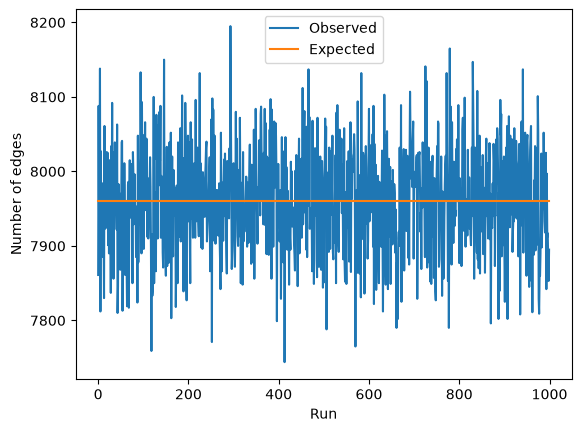

In [5]:
# Leave as-is

trials = len(observed_edges)

plt.xlabel("Run")
plt.ylabel("Number of edges")
plt.plot(range(trials), observed_edges, label="Observed")
plt.plot(range(trials), [expected_edges] * trials, label="Expected")
plt.legend()
plt.show()

Create a new generator, `generate_random_graph_avg_degree(N, kavg)` that given a target number of nodes, and a target average degree, determines the appropriate value of `p` to call `generate_random_graph(N, p)`, using the formulas seen in class.


In [ ]:
def generate_random_graph_avg_degree(N,kavg):
    p=kavg/(N-1) #el <k> mitjà entre el <k> màxima d'un node
    return generate_random_graph(N,p) #generem el graf amb aquest kavg

<font size="+1" color="red">Replace this cell with your code for ``generate_random_graph_avg_degree``.</font>

Test your new generator. First, write a function ``graph_average_degree`` that returns the average degree of a graph.

Then, generate a series of graphs with a number of nodes *N=500* of your choice and expected average degree between 0.0 and 3.0 in increments of 0.1. The observed average degree of the resulting graph should be close to the given average degree.


In [ ]:
def graph_average_degree(g):
    kavg=sum(deg for node, deg in g.degree())/g.number_of_nodes()#calcula el grau mitjà a partir dels total entre la quantitat
    return kavg
N=500
target_average_degrees=[]
observed_average_degrees=[]
for i in range(31):#31 és de 0 a 3 de 0.1 en 0.1 
    kavg=i/10 #manera més senzilla de agafar el grau mitjà
    target_average_degrees.append(kavg) #l'objectiu
    g=generate_random_graph_avg_degree(N,kavg)
    mitja=graph_average_degree(g)
    observed_average_degrees.append(mitja)#el que ens acaba sortint utilitznat totes les formules anteriors.





<font size="+1" color="red">Replace this cell with your code for ``graph_average_degree`` and for testing the generator.</font>

The following compares visually the given average degree with the observed average degree.


C:\Users\POL\AppData\Local\Temp\ipykernel_21256\1970829798.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


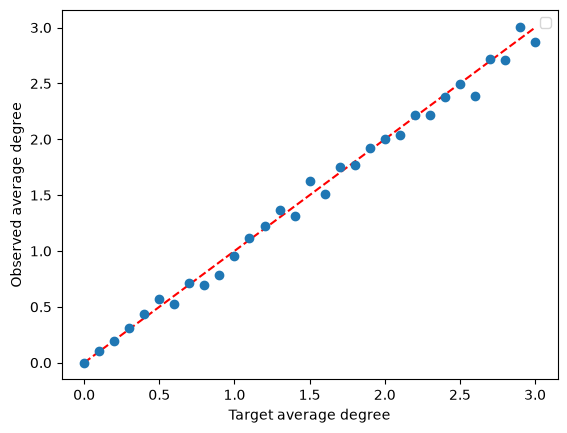

In [8]:
# Leave as-is

#!! Be careful make sure to run the previous cell just before running this one as we will be using some of the variables later and it can cause issues

plt.xlabel("Target average degree")
plt.ylabel("Observed average degree")
plt.scatter(target_average_degrees, observed_average_degrees)
plt.plot([0,max(target_average_degrees)], [0,max(target_average_degrees)], 'r--', zorder= 0)
plt.legend()
plt.show()

## 1.2. Measure connectivity


Create a function `is_connected(g)` that given a graph, answers True if the graph is connected, False otherwise. Do not use the built-in `is_connected` function of NetworkX, but feel free to use the function `nx.has_path(g, source, target)`.

Use the `itertools.combinations(G.nodes, 2)` function described above.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code for *is_connected(g)*, include comments to explain what you are doing at each step.</font>

In [ ]:
def is_connected(g):
    for u,v in itertools.combinations(g.nodes,2):#avaluem cada parell de nodes
        if nx.has_path(g,u,v):#si hi ha camí
            continue
        else:
            return False
    return True # al final ja que hi ha d'haver camí en tot el or complet


The following code, which you should leave as-is, returns the size of the largest connected component on a graph.


In [10]:
# Leave as-is

def size_largest_cc(G):

    # Obtain the list of connected components of the graph sorted from largest to smallest
    Gcc = sorted(nx.connected_components(G), key=len, reverse=True)

    # Selects the first connected component in that list
    G0 = G.subgraph(Gcc[0])

    # Returns its number of nodes
    return G0.number_of_nodes()

Create a series of ER graphs having *N=1000* nodes and target average degree  between *0.2* and *2.0* (e.g. *0.2, ..., 2.0*) with step *0.05* . Record: (1) their observed average degrees and (2) the size of their largest connected component as a fraction of the total number of nodes.

You can use the following skeleton:

```python
N = 1000
target_average_degrees = np.arange(0.2, 2.0, 0.05)

largest_cc_sizes = []
average_degrees = []

for target_average_degree in target_average_degrees:
    
    # Generate graph
    g = generate_random_graph_avg_degree(N, target_average_degree)
    assert g.number_of_nodes() == N, "Wrong number of nodes"
    
    # Obtain observed average degree
    average_degree = # YOUR CODE HERE
    average_degrees.append(average_degree)
    
    # Obtain size of largest connected component as a fraction of the total number of nodes
    largest_cc_size = # YOUR CODE HERE
    largest_cc_sizes.append(largest_cc_size)
```

<font size="+1" color="red">Replace this cell with your code to generate the data for the plot .</font>

In [ ]:
N = 1000
target_average_degrees = np.arange(0.2, 2.0, 0.05)

largest_cc_sizes = []
average_degrees = []

for target_average_degree in target_average_degrees:
    
    # Generate graph
    g = generate_random_graph_avg_degree(N, target_average_degree)
    assert g.number_of_nodes() == N, "Wrong number of nodes"
    
    # Obtain observed average degree
    average_degree =graph_average_degree(g)#calculem el grau mitjà amb la funció vista anteriorment
    average_degrees.append(average_degree)
    
    # Obtain size of largest connected component as a fraction of the total number of nodes
    largest_cc_size = size_largest_cc(g)#troba el camí més llarg amb la formula donada
    largest_cc_sizes.append(largest_cc_size)

The following code shows this visually.


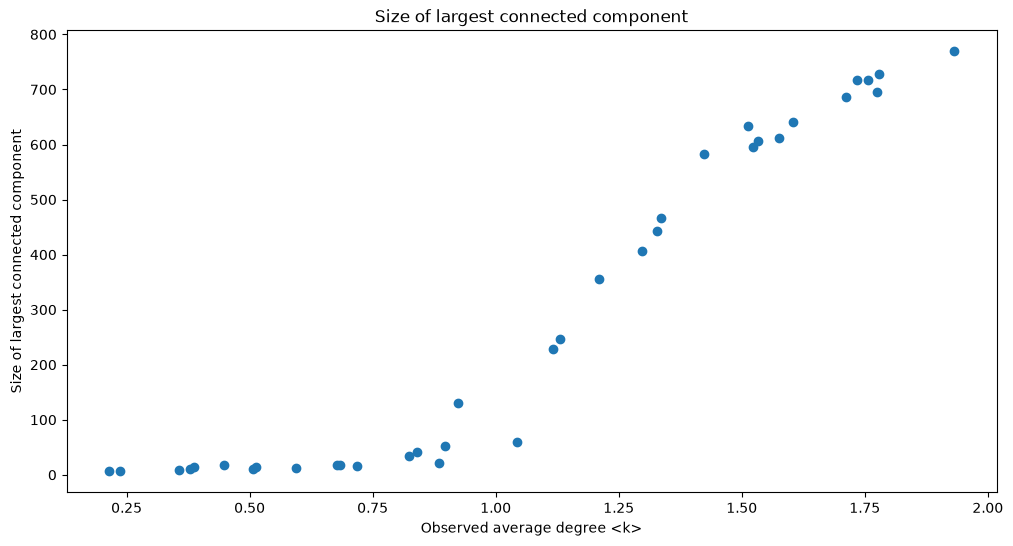

In [12]:
# LEAVE AS-IS

plt.figure(figsize=(12,6))
plt.scatter(average_degrees, largest_cc_sizes)
plt.title("Size of largest connected component")
plt.xlabel("Observed average degree <k>")
plt.ylabel("Size of largest connected component")
plt.show()

1) Es veu clarament en el gràfic anterior que la corba que formen els punts incrementa a partir de <k>=1. Això ve causat perque cada vegada hi ha de mitjana més enllacos i per tant, creix de manera accelerada.

2) En aquest cas trobem un increment en una zona entre el <k>=1 i <k>=1.2. Per tant, es troba en una zona molt semblant a la teòrica. 

## 1.3. Degree distributions and Cumulative Degree Distributions

Create another function `print_er_statistics(g,p)` that given an ER graph and a probability *p* prints:

* its observed average degree *&lt;k&gt;*
* its expected average degree given *N* and *p*, using the formula seen in class

You can get a list of *(node, degree)* pairs by invoking `g.degree()`, or ask for the degree of node *u* using `g.degree(u)`.


In [ ]:
def print_er_staditics(g,p):
    k=sum(deg for node, deg in g.degree())/g.number_of_nodes()#agafem el grau mitjà
    expected=p*(g.number_of_nodes()-1) #veiem que el esperat és la probabilitat per N-1 com hem fet abans
    print(f"Observed average degree <k> = {k}, Expected average degree {expected}")
    return
N=1000
print_er_staditics(generate_random_graph(N,0.01),0.01)#generem 3 diferents per veure les diferències
print_er_staditics(generate_random_graph(N,0.03),0.03)
print_er_staditics(generate_random_graph(N,0.1),0.1)


Observed average degree <k> = 10.038, Expected average degree 9.99
Observed average degree <k> = 30.246, Expected average degree 29.97
Observed average degree <k> = 99.28, Expected average degree 99.9


You can use the following function (as-is, or modified) to plot the degree distribution in a graph.

In [14]:
# Leave as-is or modify if you want
def plot_degree_distributions(g_list, p_values):
    plt.figure(figsize=(12, 6))

    for g, p in zip(g_list, p_values):
        degree_dict = dict(g.degree())
        degree_sequence = list(degree_dict.values())

        prob, bin_edges = np.histogram(
            degree_sequence,
            bins=range(1, np.max(degree_sequence) + 2),
            density=True
        )

        plt.plot(bin_edges[:-1], prob, 'o-', label=f'p={p}')

    plt.title("Probability Density Function (Degree Distribution)")
    plt.xlabel("Degree")
    plt.ylabel("Probability")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()


def plot_cumulative_degree_distributions(g_list, p_values):
    plt.figure(figsize=(12, 6))

    for g, p in zip(g_list, p_values):
        degree_dict = dict(g.degree())
        degree_sequence = list(degree_dict.values())

        degree_counts, bin_edges = np.histogram(
            degree_sequence,
            bins=range(1, np.max(degree_sequence) + 2),
            density=True
        )

        cumulative_distribution = np.cumsum(degree_counts[::-1])[::-1]

        plt.plot(bin_edges[:-1], cumulative_distribution, 'o-', label=f'p={p}')

    plt.title("Cumulative Degree Distribution (P(k' ≥ k))")
    plt.xlabel("Degree (k)")
    plt.ylabel("Cumulative Probability")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()


<font size="+1" color="red">Replace this cell with the generation of four graphs with fixed *N* between 1500 and 3000, and different probabilities *p*. Start with a small probability *p* that yields a sparse graph, and increase it gradually. Not all graphs need to be connected. For these graphs use plot_degree_distributions and plot_cumulative_degree distributions.</font>

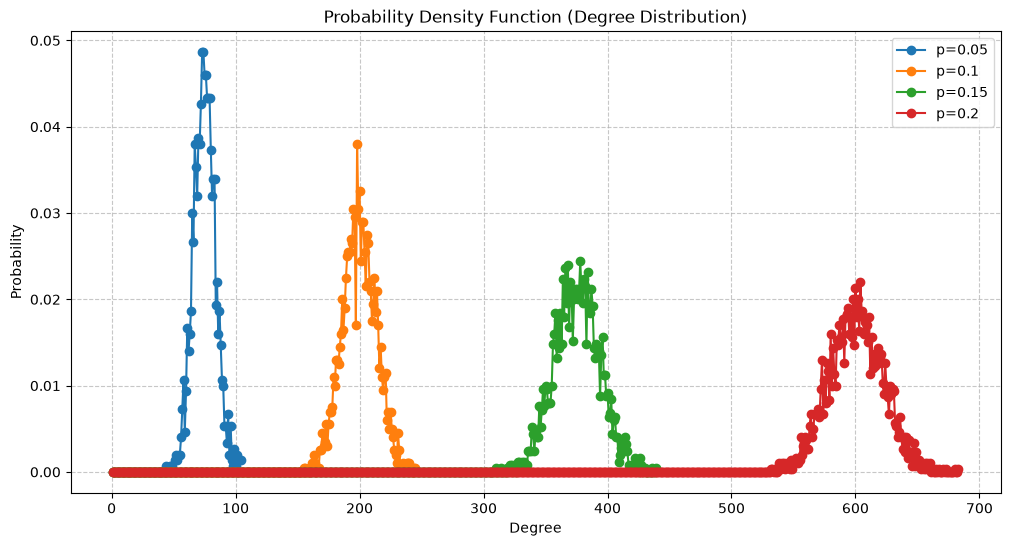

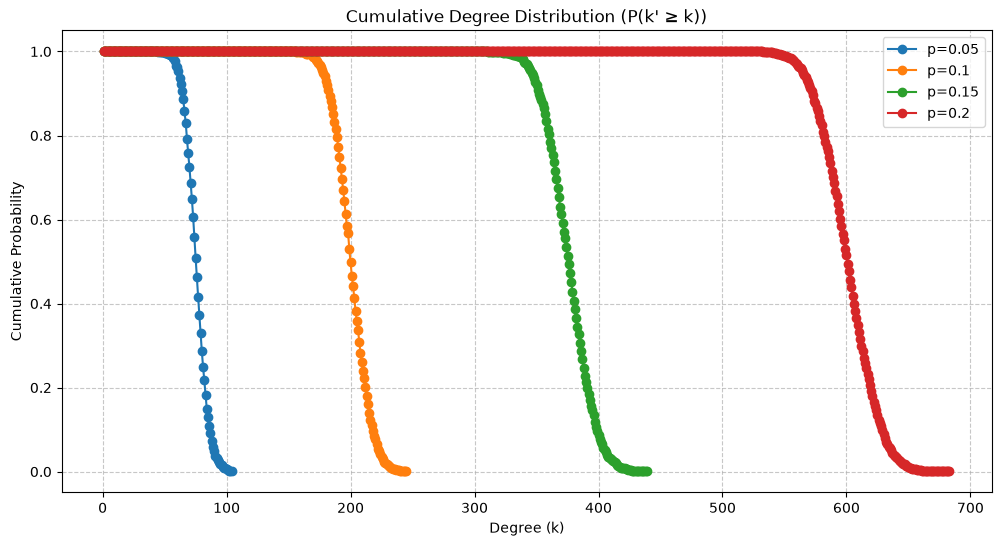

In [ ]:
nodes=[1500,2000,2500,3000]#triem fer-ho cada 500 nodes
probs=[0.05,0.1,0.15,0.2]#triem de 0.05 fins 0.2 cada 0.05
graphs=[]

for i in range(4):
    graphs.append(generate_random_graph(nodes[i],probs[i]))#fem randoms i avaluem la densitat de probabilitat i l'acumulativa
plot_degree_distributions(graphs,probs)
plot_cumulative_degree_distributions(graphs,probs)

# 2. Preferential attachment (BA) generator

Write code for creating a BA graph.

The following function, `select_with_probability(x, m, p)` selects *m* elements from set *x* according to probabilities in *p*, without replacement. It uses [numpy.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) to do this.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [16]:
# LEAVE AS-IS

def select_with_probability(x, m, p):
    return np.random.choice(x, size=m, replace=False, p=p)

The next cell, which you should leave as-is, tests this function.

In [17]:
# LEAVE AS-IS

trials = 1000
vector = ['a', 'b', 'c']
probabilities = [0.75, 0.13, 0.12]

all_selected = []
for i in range(trials):
    selected = select_with_probability(vector, 1, probabilities)[0]
    all_selected.append(selected)

for i, p in zip(vector, probabilities):
    print("Element {:s} was selected {:d} times, expected {:.0f}".format(i, all_selected.count(i), trials*p) )

Element a was selected 759 times, expected 750
Element b was selected 132 times, expected 130
Element c was selected 109 times, expected 120


Write code for creating a BA graph.

Start by creating an auxiliary function, `select_targets(g, m)` that selects *m* target nodes in a graph *g*, with probabilities proportional to the degrees of the nodes.

```python
def select_targets(g, m):

    # Check if feasible
    N = g.number_of_nodes()  
    if N < m:
        raise ValueError('Graph has less than m nodes')

    # Compute sum of degree
    sum_degree = 0

    # YOUR CODE HERE: COMPUTE SUM OF DEGREE OF NODES
    if sum_degree == 0:
        raise ValueError('Graph as no edges')

    # Compute probabilities
    probabilities = []
    for (node, degree) in g.degree():
        # YOUR CODE HERE: COMPUTE PROBABILITY OF SELECTING NODE u
        # THEN APPEND IT TO probabilities USING probabilities.append(...)

    # Sample
    selected = select_with_probability(g.nodes(), m, probabilities)

    return selected
´´´

In [ ]:
def select_targets(g, m):

    # Check if feasible
    N = g.number_of_nodes()  
    if N < m:
        raise ValueError('Graph has less than m nodes')

    # Compute sum of degree
    sum_degree = 0
    sum_degree=sum(deg for node, deg in g.degree())#fem com fem el kavg pero sense dividir entre la N de nodes
    if sum_degree == 0:
        raise ValueError('Graph as no edges')

    # Compute probabilities
    probabilities = []
    for (node, degree) in g.degree():
        p= degree/sum_degree #calculem la probabilitat de cada grau
        probabilities.append(p)
        

    # Sample
    selected = select_with_probability(g.nodes(), m, probabilities)

    return selected

<font size="+1" color="red">Replace this cell with your implementation of select_targets.</font>

Now, create a function `generate_preferential_attachment_graph(N, m0, m)` that:

1. Checks that *m <= m0* or raises a ValueError
1. Creates an empty graph
1. Adds nodes numbered from *0* to *m<sub>0</sub> - 1* to the graph
1. Creates a cycle by linking node *0* to node *1*, node *1* to node *2*, ..., node *m<sub>0</sub>-1* to node *0*
1. For every node *u* numbered from *m<sub>0</sub>* to *N - 1*
   1. Select *m* targets for this node using `select_targets`
   1. Add node *u* (remember to select targets **before** adding the node *u*)
   1. Link each node *u* to each of the *m* targets
1. Returns the graph

To test your code, you can do small experiments with, e.g., *N=100, m<sub>0</sub>=5, m=5* or *N=500, m<sub>0</sub>=2, m=1*, but do not include these small experimens with your deliverable.


In [ ]:
def generate_preferential_attachment_graph(N,m0,m):
    if m>m0:#comprovació per poder generar-lo sinó no funciona
        raise ValueError
    g=nx.Graph()
    for i in range(m0):
        g.add_node(i) #afegim m0 nodes
    for i in range(m0):
        g.add_edge(i,(i+1)%m0) #afegim una aresta a cada (i,i+1) i quan arriba al màxim el que fa és enllaçar-lo a 0 per tant, cicle
    for u in range(m0,N):
        x=select_targets(g,m) #calculem quins edges haig de connectar a cada node
        g.add_node(u) #afegim cada node un com havent calculat els edges
        for v in x:
            g.add_edge(u,v)#els connectem
    return g


        

<font size="+1" color="red">Replace this cell with your implementation of generate_preferential_attachment_graph(N, m0, m), include comments to explain what you are doing at each step.</font>

In [33]:
# Leave as is
def estimate_alpha_mle(degrees, k_min=1):
    degrees = np.array(degrees)
    degrees = degrees[degrees >= k_min]
    n = len(degrees)
    alpha = 1 + n / np.sum(np.log(degrees / (k_min - 0.5)))
    return alpha

```python
def plot_degree_distribution_loglog(g, k_min=1):
    degree_dict = dict(g.degree())
    degree_sequence = np.array(list(degree_dict.values()))
    degree_sequence = degree_sequence[degree_sequence >= k_min]
    
    # Compute empirical histogram
    prob, bin_edges = np.histogram(
        degree_sequence,
        bins=range(k_min, np.max(degree_sequence)+2),
        density=True
    )
    
    x = bin_edges[:-1]
    y = prob
    
    # Remove zeros (log scale)
    mask = y > 0
    x = x[mask]
    y = y[mask]
    
    # Estimate alpha using MLE
    # ONE LINE TO FILL:
    alpha=
    
    # Compute fitted power-law line
    # Normalize to match the first bin of the empirical data
    y_fit=
    
    # Plot
    plt.figure(figsize=(12,6))
    plt.loglog(x, y, 'o', alpha=0.7, label='Empirical data')
    plt.loglog(x, y_fit, '--', color='red', label=f'MLE Power-law fit: α={alpha:.2f}')
    
    plt.xlabel("Degree (k)")
    plt.ylabel("P(k)")
    plt.title("Degree Distribution (Log-Log Scale)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
```

1. Complete plot_degree_distribution_log_log so that the resulting graph has the corresponding power-law fit.
2. Execute for two preferential attachment (BA) graphs with 5000 nodes, and values of *m0* and *m* (in the range 1-10)

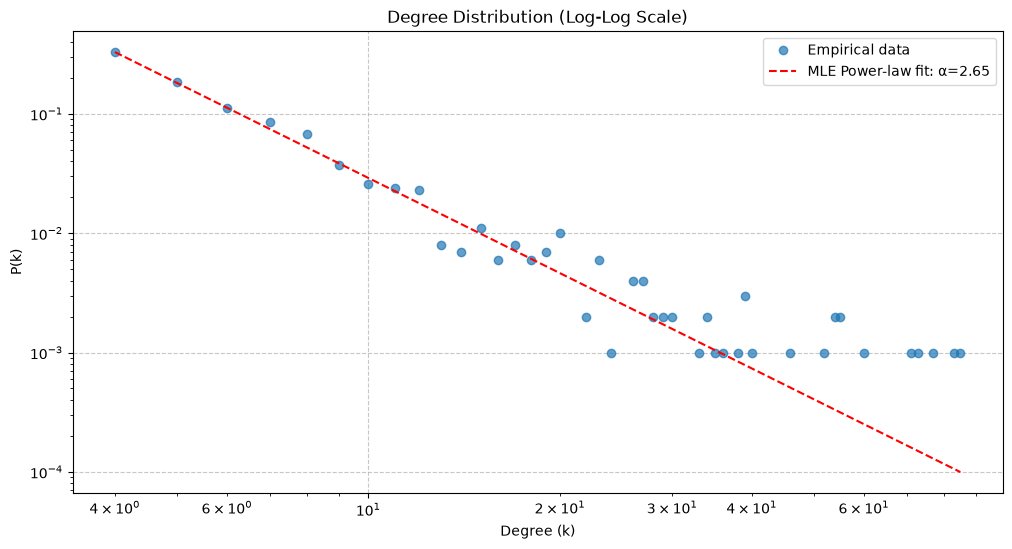

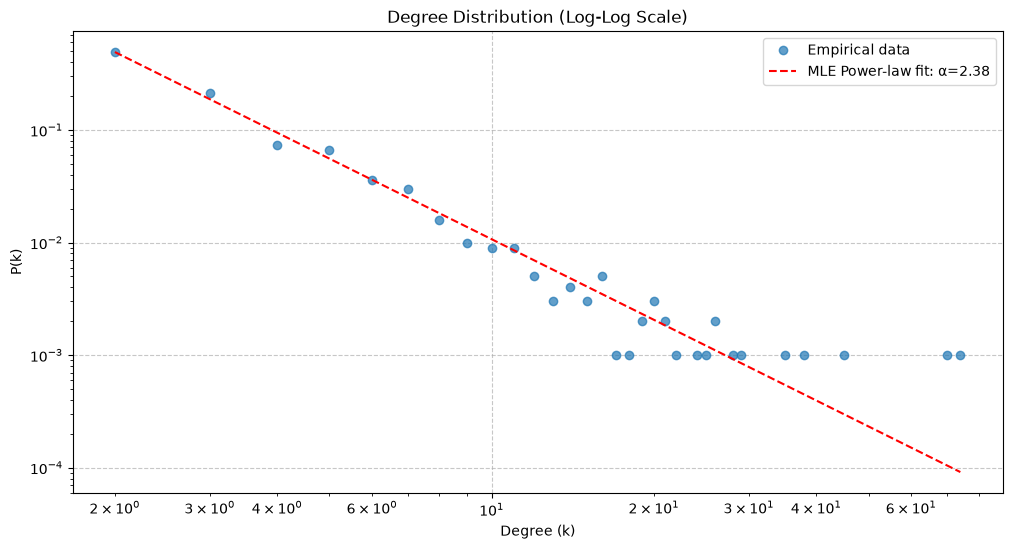

In [ ]:
def plot_degree_distribution_loglog(g, k_min=1):
    degree_dict = dict(g.degree())
    degree_sequence = np.array(list(degree_dict.values()))
    degree_sequence = degree_sequence[degree_sequence >= k_min]
    
    # Compute empirical histogram
    prob, bin_edges = np.histogram(
        degree_sequence,
        bins=range(k_min, np.max(degree_sequence)+2),
        density=True
    )
    
    x = bin_edges[:-1]
    y = prob
    
    # Remove zeros (log scale)
    mask = y > 0
    x = x[mask]
    y = y[mask]
    
    # Estimate alpha using MLE
    alpha=estimate_alpha_mle(degree_sequence,k_min)#utilitzem l'alpha vista anteriorment per calcular-la i fer el BA
    
    # Compute fitted power-law line
    y_fit=y[0]*(x/x[0])**(-alpha)#normalitzem a partir de la x
    
    # Plot
    plt.figure(figsize=(12,6))
    plt.loglog(x, y, 'o', alpha=0.7, label='Empirical data')
    plt.loglog(x, y_fit, '--', color='red', label=f'MLE Power-law fit: α={alpha:.2f}')
    plt.xlabel("Degree (k)")
    plt.ylabel("P(k)")
    plt.title("Degree Distribution (Log-Log Scale)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
g1=generate_preferential_attachment_graph(1000,6,4)
g2=generate_preferential_attachment_graph(1000,4,2)
plot_degree_distribution_loglog(g1,4)
plot_degree_distribution_loglog(g2,2)

En una BA network la alpha es troba al voltant del 3. Hem realitzat un primer test amb k_min=1 el qual ens donava una alpha de 1,5 aproximadament i quan hem igualat k_min=m doncs la gràfica queda relativament sobre de la línia marcada per l'alpha aspecte que ens diu que l'aproximació és bastant correcte.

# 3. ER and BA graph Comparison

In [36]:
#Leave as is
def plot_degree_distribution(g):
    degree_dict = dict(g.degree())
    degree_ordered = OrderedDict(sorted(degree_dict.items(), key=lambda x: x[1], reverse=True))
    degree_sequence = list(degree_ordered.values())
    prob, bin_edges = np.histogram(degree_sequence, bins=range(1,np.max(degree_sequence)+2), density=True)
    plt.figure(figsize=(12,6))
    plt.loglog(bin_edges[:-1], prob, 'o-')
    plt.title("Probability density function")
    plt.xlabel("degree")
    plt.ylabel("probability")
    plt.autoscale(enable=True, axis='both')
    plt.show()

To draw a graph, you can use:

```python
nx.draw_networkx(g)
```

You can have more control over the visualization of the graph, such as setting the figure size, removing the axis, using a particular layout algorithm, or changing the node size or color:

```python
plt.figure(figsize=(12,6))
plt.axis('off')
pos=nx.spring_layout(g)
nx.draw_networkx(g, pos, with_labels=True, node_size=1000, node_color='lightgreen')
```

Tip: In the graph drawings of ER and BA graphs on this report you can use options `with_labels=False, node_size=10` (you can play with different values for `node_size`)

<font size="+1" color="red"> Generate an ER and a BA graph of size 500. Draw them and plot their degree distribution. Use p=0.01, m0=4 and m=1.</font>

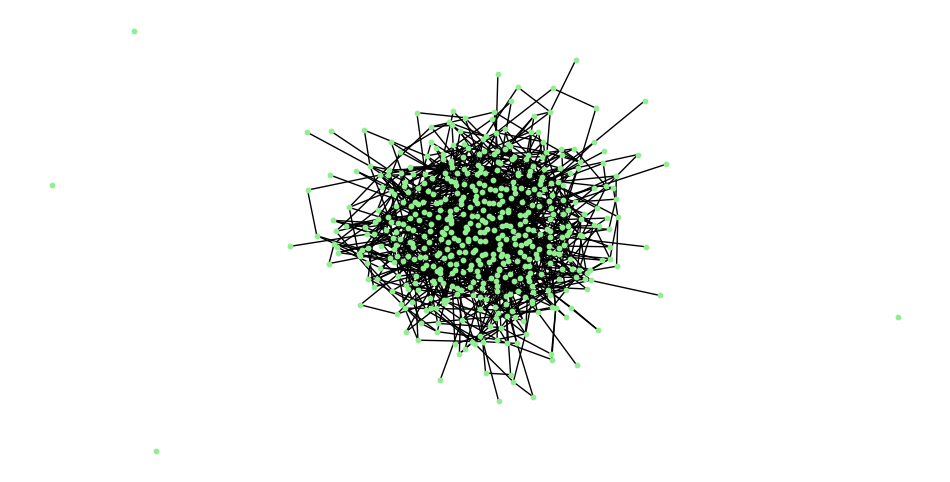

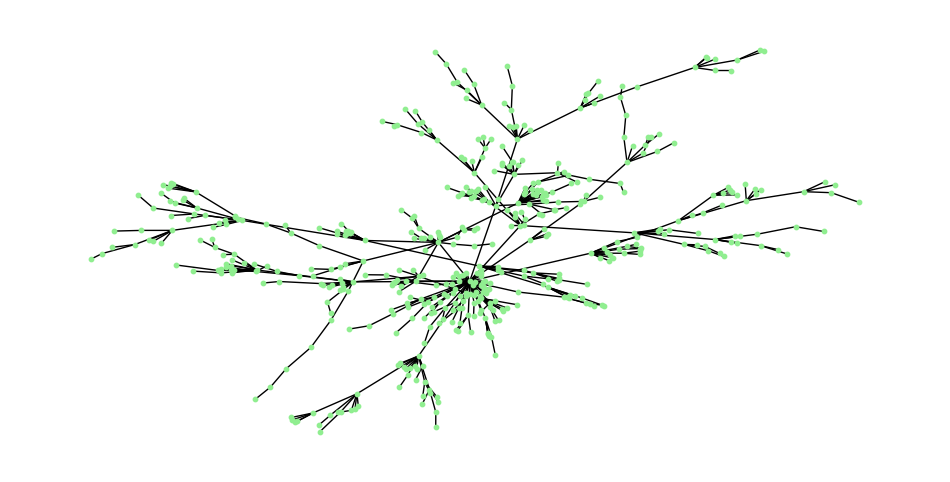

In [ ]:
ER=generate_random_graph(500, 0.01)#fem el gràfic ER
BA=generate_preferential_attachment_graph(500,4,1)#fem el gràfic BA
#els printejem primer un i després l'altre
plt.figure(figsize=(12,6))
plt.axis('off')
pos_er=nx.spring_layout(ER)
nx.draw_networkx(ER, pos_er, with_labels=False, node_size=10, node_color='lightgreen')
plt.figure(figsize=(12,6))
plt.axis('off')
pos_ba=nx.spring_layout(BA)
nx.draw_networkx(BA, pos_ba, with_labels=False, node_size=10, node_color='lightgreen')

<font size="+1" color="red">Give a very brief comment on the differences between the two graphs regarding:
1. Structure of the network. 
1. The probability density function.</font>

El que veiem en els gràfics és un grau bastant alt en alguns pocs nodes amb hubs i la resta grau molt baix com en el cas del BA això ho provoca el m=1 que cada node nou només enllaça a un antic i el fet de que els nodes entrant sempre volen ajuntar-se als hubs més grans. En canvi el ER té tots els graus concentrats al voltant de la mitjana causat per la probabilitat ja que cada parella s'uneix a una altra a partir de la probabilitat i per tant, cada node s'allunya molt poc del grau mitjà del graf.

En el segon aspecte, en quant a la funció de densitat de probabilitat podem dir que el ER formaria probablement una campana. En canvi el BA no hi ha cap grau generalitzat i per tant, pot haver-hi tant graus realment molt alts i graus que tenen valor molt baix, aixó és perquè la distribució segueix la llei de potències.

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>